# Drift and noise of B: do blocks sustain themselves?

For each day, how B changes by tomorrow, as a function of B today. Red noise predicts a straight-line drift and constant noise. Results go to `results/ERA40_winter_B_analysis.sqlite`.

In [1]:
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

B_daily = pd.read_parquet("../results/ERA40_B_index_daily_1957-2002_TH08.parquet").rename(columns=int)   # rows = days, columns = longitude (°E)
WINTERS = range(1958, 2002)   # DJF 1957/58 - 2000/01, labelled by January
lons = B_daily.columns.to_numpy()
B_winters = [B_daily.loc[f"{y-1}-12":f"{y}-02"].to_numpy() for y in WINTERS]

## Day pairs

Today's B, the change to tomorrow, and whether today is sector-blocked (SB). Pairs never span two winters.

In [2]:
def sector_blocking(B):
    """SB: LIB at 3 neighbouring longitudes inside the 45° sector centred on each longitude."""
    lib = B > 0
    run = lib & np.roll(lib, 1, axis=1) & np.roll(lib, -1, axis=1)
    sb = np.zeros_like(lib)
    for k in range(-3, 4):
        sb |= np.roll(run, k, axis=1)
    return sb

today = np.concatenate([b[:-1] for b in B_winters])                  # (pairs, longitudes)
change = np.concatenate([b[1:] - b[:-1] for b in B_winters])
sb_today = np.concatenate([sector_blocking(b)[:-1] for b in B_winters])

states = {"all": np.ones_like(sb_today), "SB": sb_today, "no SB": ~sb_today}

## Drift and noise in bins of B

Drift = mean change to tomorrow; noise = variance of that change. 2 K bins, kept if they hold at least 30 days.

In [3]:
BIN, MIN_DAYS = 2.0, 30
edges = np.arange(-50, 40 + BIN, BIN)

rows = []
for state, mask in states.items():
    for j, lon in enumerate(lons):
        b, d = today[mask[:, j], j], change[mask[:, j], j]
        idx = np.digitize(b, edges) - 1
        for i in range(len(edges) - 1):
            sel = idx == i
            n = int(sel.sum())
            if n >= MIN_DAYS:
                rows.append(dict(lon=int(lon), state=state, b_center=edges[i] + BIN / 2, n=n,
                                 drift=d[sel].mean(), drift_se=d[sel].std(ddof=1) / np.sqrt(n),
                                 noise_var=d[sel].var(ddof=1)))
drift_noise = pd.DataFrame(rows)

## Summary per longitude

Straight-line fit of change on B, separately for B ≤ 0, B > 0 and all days. Memory φ = 1 + slope (red noise: the same φ on both sides); noise = variance left over after the fit.

In [4]:
rows = []
for state, mask in states.items():
    for j, lon in enumerate(lons):
        b, d = today[mask[:, j], j], change[mask[:, j], j]
        row = dict(lon=int(lon), state=state)
        for side, sel in [("below0", b <= 0), ("above0", b > 0), ("all", np.ones_like(b, bool))]:
            if sel.sum() >= MIN_DAYS:
                slope, intercept = np.polyfit(b[sel], d[sel], 1)
                resid = d[sel] - (slope * b[sel] + intercept)
                row.update({f"phi_{side}": 1 + slope, f"noise_var_{side}": resid.var(ddof=2), f"n_{side}": int(sel.sum())})
        rows.append(row)
summary = pd.DataFrame(rows)

## Save to the database

In [5]:
with sqlite3.connect("../results/ERA40_winter_B_analysis.sqlite") as con:
    drift_noise.to_sql("drift_noise", con, if_exists="replace", index=False)
    summary.to_sql("drift_noise_summary", con, if_exists="replace", index=False)
print(len(drift_noise), "rows in drift_noise,", len(summary), "rows in drift_noise_summary")

3449 rows in drift_noise, 216 rows in drift_noise_summary


## Drift and noise at three longitudes (TH Fig. 4a's)

Red noise: drift on a straight line, noise flat. Dotted line: B = 0 (the LIB threshold).

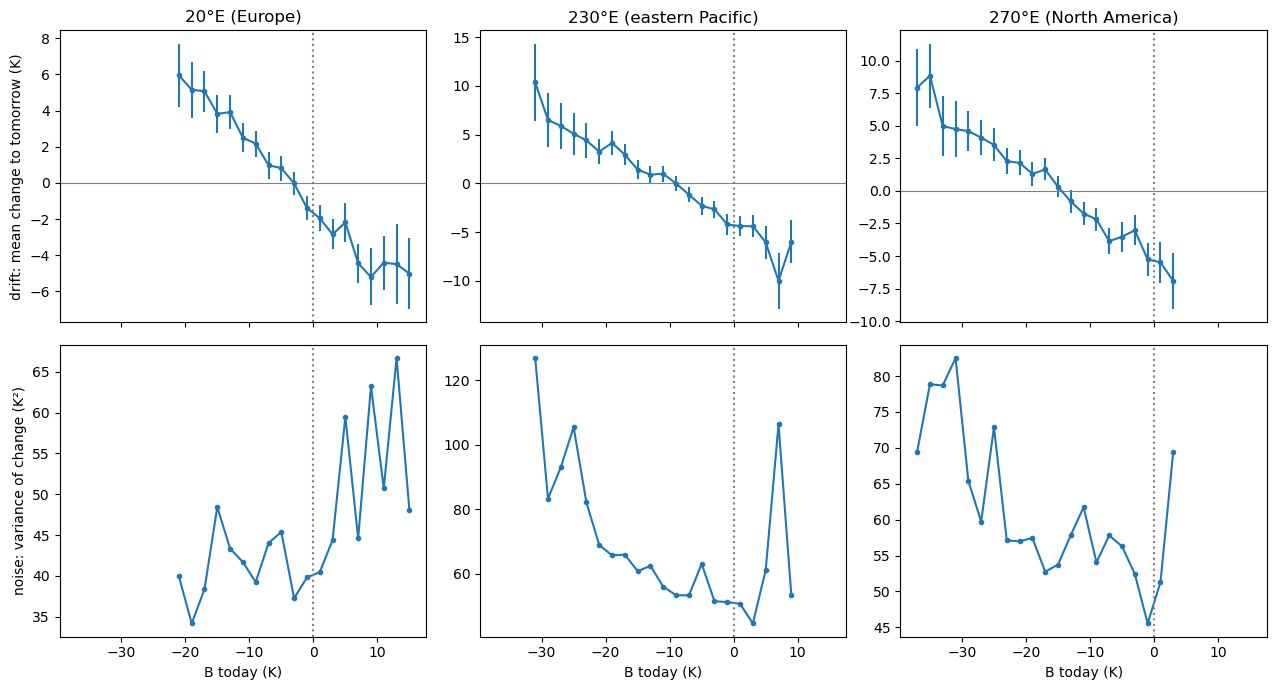

In [6]:
EXAMPLE_LONS = {20: "Europe", 230: "eastern Pacific", 270: "North America"}

fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharex=True)
for col, (lon, label) in enumerate(EXAMPLE_LONS.items()):
    d = drift_noise[(drift_noise.lon == lon) & (drift_noise.state == "all")]
    axes[0, col].errorbar(d.b_center, d.drift, yerr=2 * d.drift_se, fmt="o-", markersize=3)
    axes[0, col].axhline(0, color="gray", linewidth=0.8)
    axes[0, col].set_title(f"{lon}°E ({label})")
    axes[1, col].plot(d.b_center, d.noise_var, "o-", markersize=3)
    axes[1, col].set_xlabel("B today (K)")
    for ax in axes[:, col]:
        ax.axvline(0, color="gray", linestyle=":")
axes[0, 0].set_ylabel("drift: mean change to tomorrow (K)")
axes[1, 0].set_ylabel("noise: variance of change (K²)")
plt.tight_layout()
plt.show()

## Memory and noise by longitude

Top: local test (B > 0 vs B ≤ 0). Middle: sector test (SB vs no SB). Bottom: noise when B > 0 relative to B ≤ 0 (below 1 = smaller kicks while blocked).

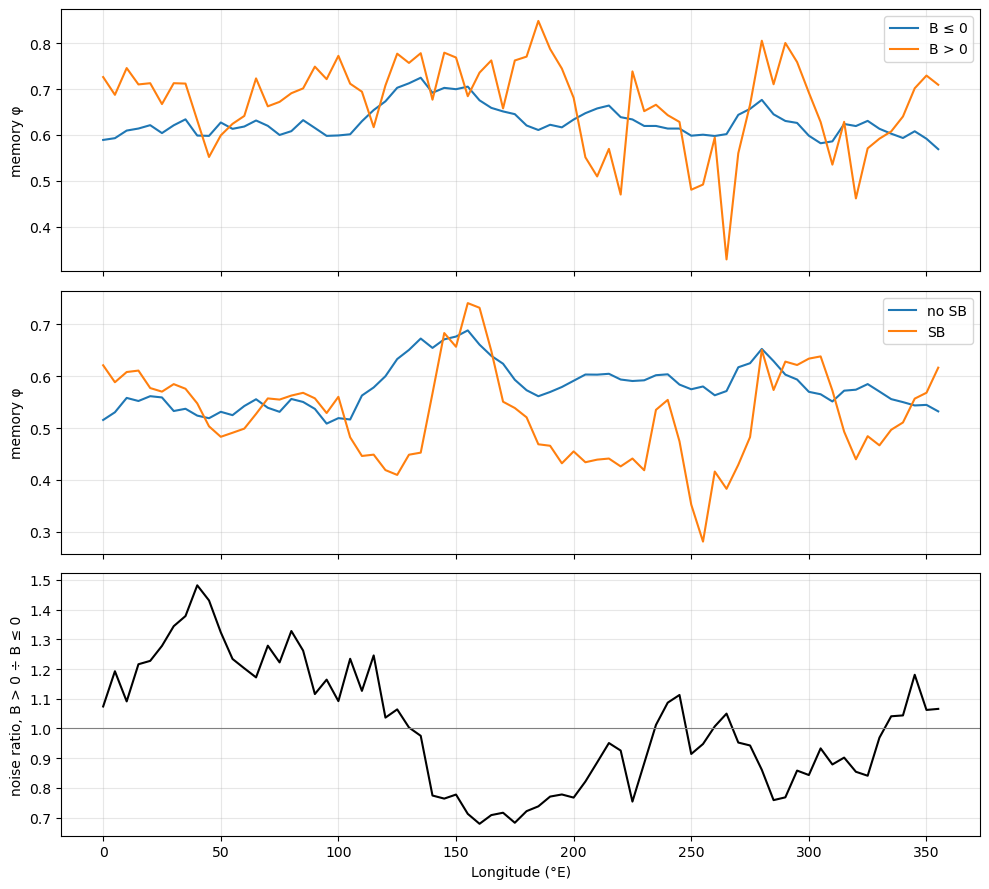

In [7]:
s_all = summary[summary.state == "all"]
s_sb, s_no = summary[summary.state == "SB"], summary[summary.state == "no SB"]

fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
axes[0].plot(s_all.lon, s_all.phi_below0, label="B ≤ 0")
axes[0].plot(s_all.lon, s_all.phi_above0, label="B > 0")
axes[0].set_ylabel("memory φ")
axes[0].legend()
axes[1].plot(s_no.lon, s_no.phi_all, label="no SB")
axes[1].plot(s_sb.lon, s_sb.phi_all, label="SB")
axes[1].set_ylabel("memory φ")
axes[1].legend()
axes[2].plot(s_all.lon, s_all.noise_var_above0 / s_all.noise_var_below0, color="black")
axes[2].axhline(1, color="gray", linewidth=0.8)
axes[2].set_ylabel("noise ratio, B > 0 ÷ B ≤ 0")
axes[2].set_xlabel("Longitude (°E)")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()